# Getting started — Generalized Superposition Theorem (GST)

This notebook mirrors `getting_started_sup_theorem.ipynb`, but for the **Generalized
Superposition Theorem**, which combines **topological changes** *and* an **injection
change** (e.g. a redispatch) in a single linear, solver-free reconstruction. Each
example shows the network **power flows** of the initial state, of every unitary state,
and of the final combined state.

**Available inputs** (exactly what an operator precomputes once):
* the reference state $\mathrm{PF}(P^{ref}, T^{ref})$,
* the unitary **topology** states $\mathrm{PF}(P^{ref}, T^{\tau_i})$ (reference injection),
* the unitary **injection** states $\mathrm{PF}(\delta P^k, T^{ref})$ (**reference topology**).

The modified-topology injection response $\mathrm{PF}(\delta P^k, T^{\tau_i})$ is **never** needed.

**Result.**
$$\mathrm{PF}(P^{tgt},T^{tgt}) = \alpha\, \mathrm{PF}(P^{ref},T^{ref})
 + \sum_i \beta^i\, \mathrm{PF}(P^{ref},T^{\tau_i})
 + \sum_k \mathrm{PF}(\delta P^k,T^{ref}),\qquad \alpha = 1-\sum_i\beta^i.$$

The topology states carry the **EST weights** $(\alpha,\beta^i)$; the injection states are
added in **pure superposition**. The injection enters the weights **only through the
right-hand side** of the (unchanged) EST linear system, as a flow/angle ratio on the
switched assets. With no injection change we recover the EST exactly.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import grid2op
from grid2op.Parameters import Parameters
from lightsim2grid import LightSimBackend
from grid2op.PlotGrid import PlotMatplot
from IPython.display import display
from superposition_theorem import State
from superposition_theorem.core.compute_power_flows import (
    compute_flows_GST_from_unit_act_obs,
    compute_flows_superposition_theorem_from_unit_act_obs,
)

param = Parameters()
param.ENV_DC = True                      # DC power flow, where the theorem is exact
param.MAX_LINE_STATUS_CHANGED = 99999
param.MAX_SUB_CHANGED = 99999
param.NO_OVERFLOW_DISCONNECTION = True
env = grid2op.make("l2rpn_case14_sandbox", param=param, backend=LightSimBackend(), test=True)
A = env.action_space
decimal_digit_precision = 4              # same accuracy check as the EST notebook

# network plotting helper: shows active power flows (MW) on every line
plot_helper = PlotMatplot(env.observation_space)
def show(obs, title):
    fig = plot_helper.plot_obs(obs, line_info="p")
    fig.suptitle(title, fontsize=13)
    display(fig); plt.close(fig)

## The injection lever
In Grid2Op the injection change is a **balanced redispatch** (it sums to zero, so it is
applied verbatim and superposes linearly under DC). The unitary injection state is just
`obs_start.simulate(redispatch, 0)`. We redispatch **+10 MW at the generator on
substation 2** against **-10 MW on substation 0**: these two substations are electrically
farther apart than substations 1 and 0, so the injection meaningfully reshapes the flows
and the combination with topology is a stronger test.

## Example A — two line disconnections + an injection change

In [2]:
env.set_id(0); env.reset()
obs_start, *_ = env.step(A({}))                 # reference state (all lines in service)

id_l1, id_l2 = 3, 12
redisp = [(1, +10.0), (5, -10.0)]               # balanced injection change dP: gen at sub 2 up, gen at sub 0 down

obs1, *_ = obs_start.simulate(A({"set_line_status": [(id_l1, -1)]}), 0)   # topology unit states
obs2, *_ = obs_start.simulate(A({"set_line_status": [(id_l2, -1)]}), 0)
obs_inj, *_ = obs_start.simulate(A({"redispatch": redisp}), 0)            # injection unit state

combined = A({"set_line_status": [(id_l1, -1), (id_l2, -1)], "redispatch": redisp})
obs_target, *_ = obs_start.simulate(combined, 0)                          # ground truth

p_gst, alpha, betas = compute_flows_GST_from_unit_act_obs(
    [id_l1, id_l2], obs_start, [obs1, obs2], [obs_inj], return_betas=True)
print("alpha =", round(alpha, 4), " betas =", np.round(betas, 4))
print(f"Max difference (MW): {np.max(np.abs(obs_target.p_or - p_gst))}")
assert np.all(np.round(obs_target.p_or - p_gst, decimal_digit_precision) == 0.0)

alpha = -1.0555  betas = [0.9778 1.0777]
Max difference (MW): 4.4560391216919015e-06


Network flows — initial state, the two unitary disconnection states, the unitary
injection state, and the final combined state:

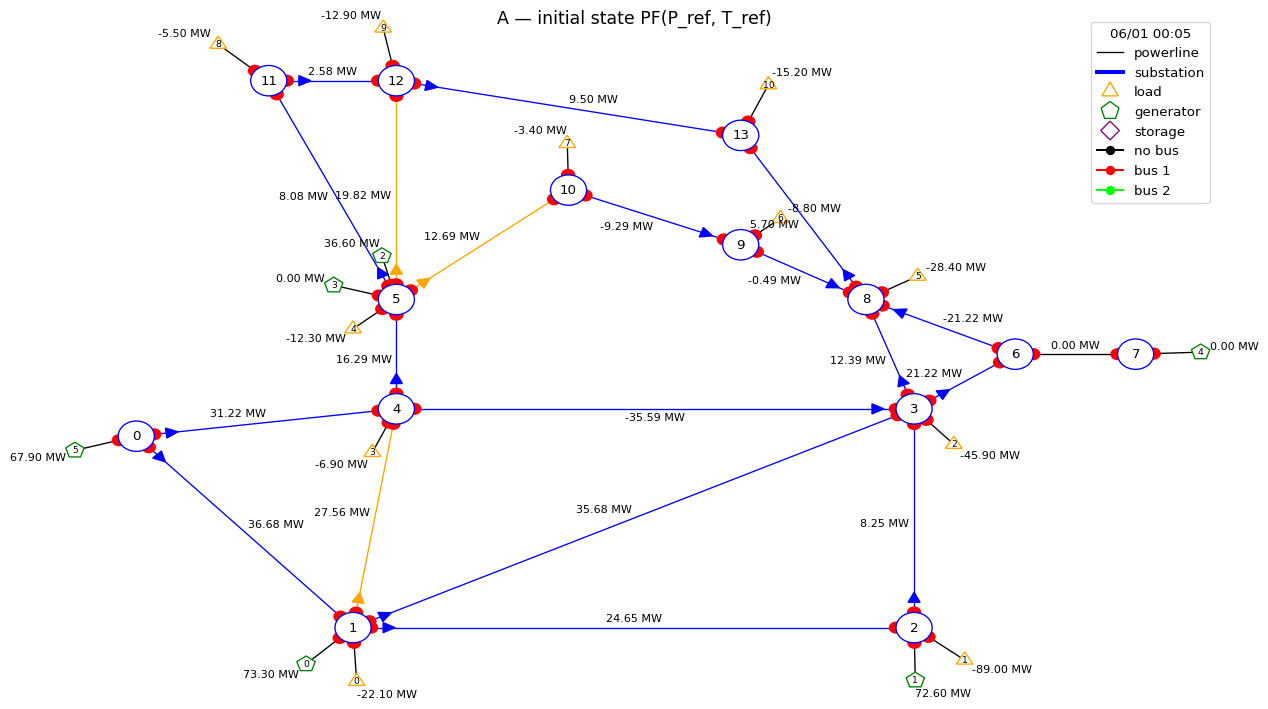

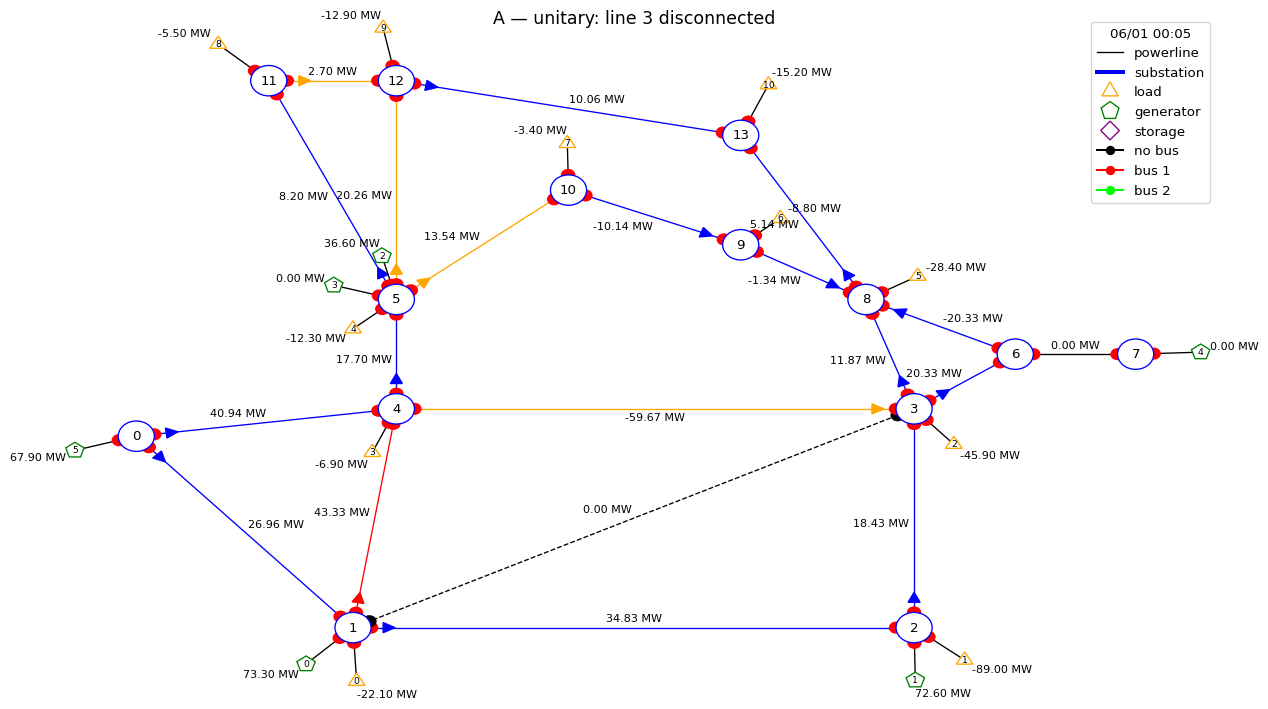

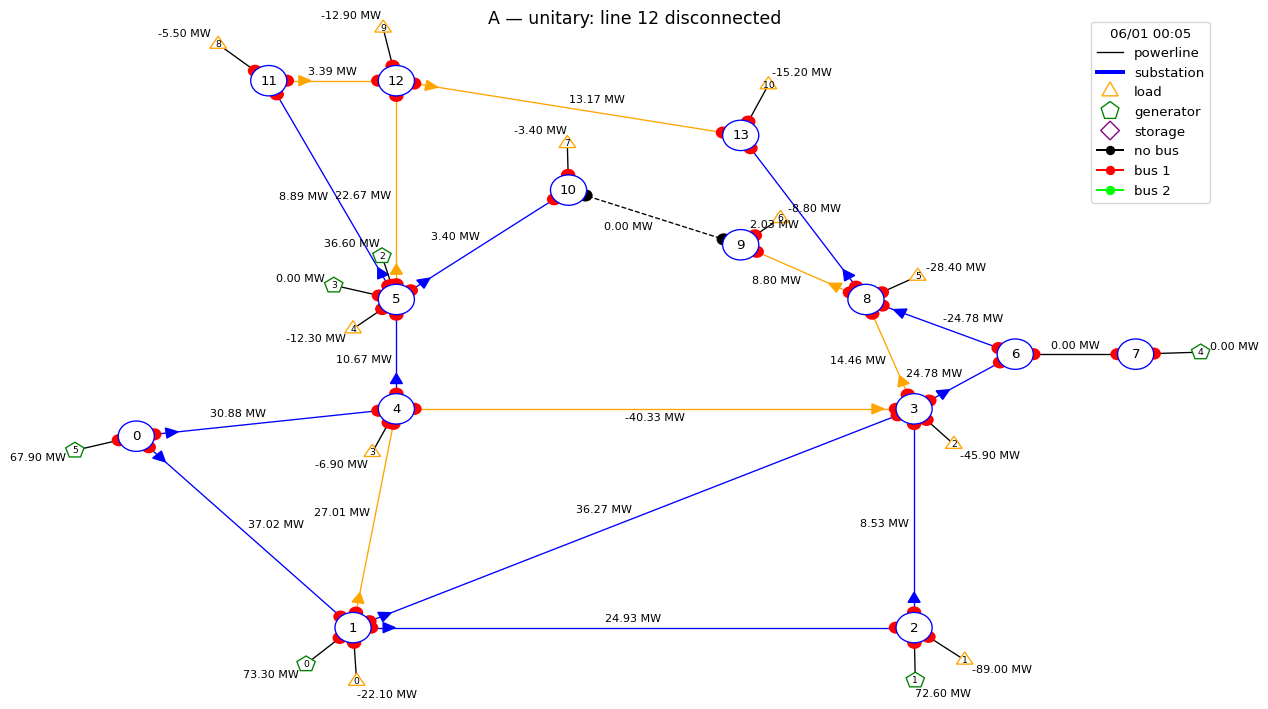

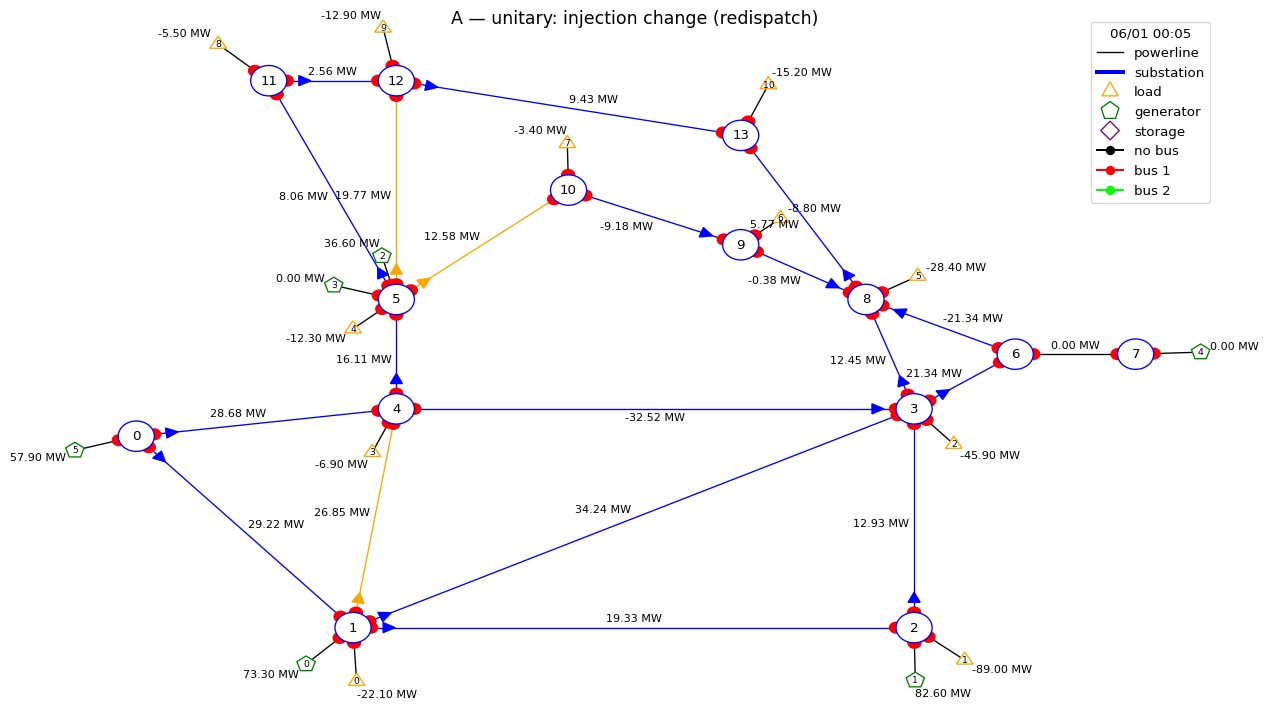

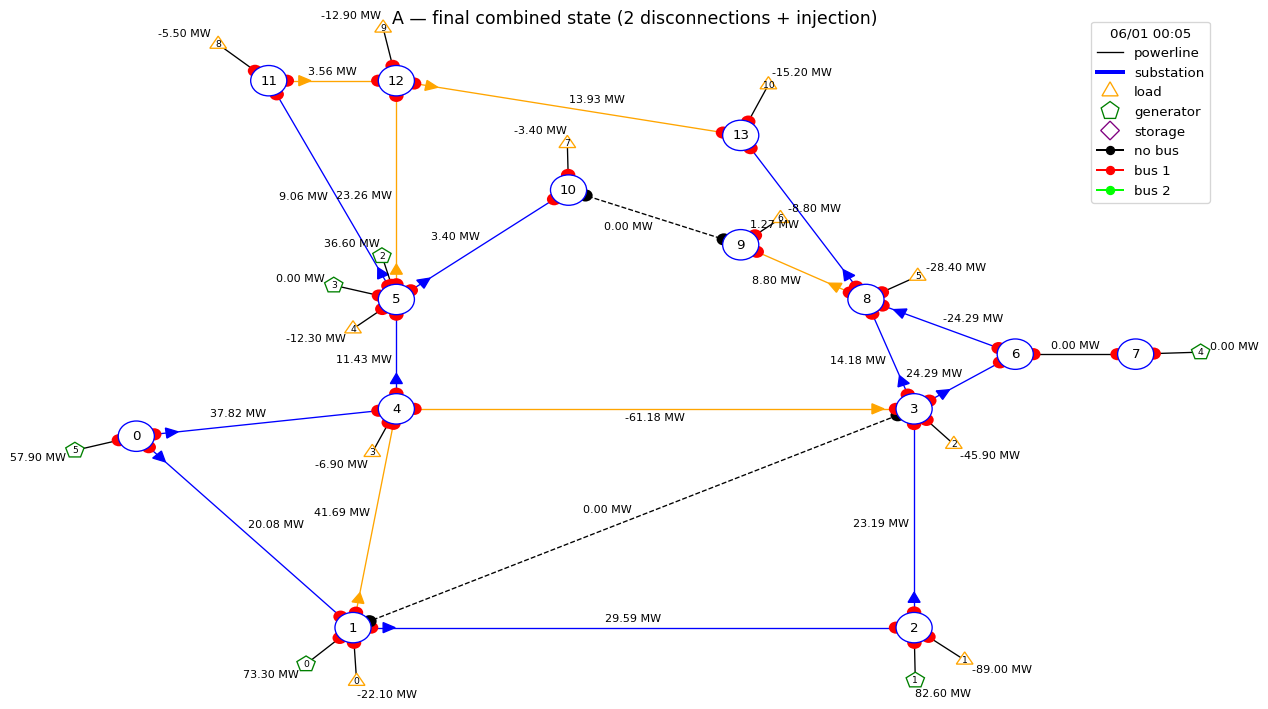

In [3]:
show(obs_start, "A — initial state PF(P_ref, T_ref)")
show(obs1, f"A — unitary: line {id_l1} disconnected")
show(obs2, f"A — unitary: line {id_l2} disconnected")
show(obs_inj, "A — unitary: injection change (redispatch)")
show(obs_target, "A — final combined state (2 disconnections + injection)")

The same result through the **object-oriented `State` API**:

In [4]:
st = State.from_grid2op_obs(obs_start, line_ids_disc_unary=[id_l1, id_l2])
st.add_injection_states_grid2op(obs_start, [A({"redispatch": redisp})])
p_gst_oo = st.compute_flows_gst(line_ids_disc=[id_l1, id_l2])
print(f"Max difference (MW): {np.max(np.abs(obs_target.p_or - p_gst_oo))}")
assert np.all(np.round(obs_target.p_or - p_gst_oo, decimal_digit_precision) == 0.0)

Max difference (MW): 4.4560391216919015e-06


**Why the injection cannot be bolted on naively.** Ignoring the injection (EST only),
or adding a separately computed injection response to the EST result, both miss the
injection's effect on the switched-line flows (which the GST puts in the right-hand side).

In [5]:
p_est_only = compute_flows_superposition_theorem_from_unit_act_obs(
    [id_l1, id_l2], [], obs_start, obs_target, [obs1, obs2])
print(f"EST only (ignores injection)      Max difference (MW): {np.max(np.abs(obs_target.p_or - p_est_only)):.4f}")
p_naive = p_est_only + (obs_inj.p_or - obs_start.p_or)
print(f"naive separable (EST_ref + dP)    Max difference (MW): {np.max(np.abs(obs_target.p_or - p_naive)):.4f}")
print(f"GST (correct)                     Max difference (MW): {np.max(np.abs(obs_target.p_or - p_gst)):.2e}")

EST only (ignores injection)      Max difference (MW): 7.0772
naive separable (EST_ref + dP)    Max difference (MW): 1.4338
GST (correct)                     Max difference (MW): 4.46e-06


## Example B — two line reconnections + an injection change
Reconnections use the angle differences $\Delta\theta$ (the reconnected lines carry no flow
at the reference topology); the GST right-hand side becomes the corresponding angle ratio.

In [6]:
env.set_id(0); env.reset()
obs_start, *_ = env.step(A({"set_line_status": [(id_l1, -1), (id_l2, -1)]}))  # ref: l1,l2 disconnected

obs1, *_ = obs_start.simulate(A({"set_line_status": [(id_l1, +1)]}), 0)
obs2, *_ = obs_start.simulate(A({"set_line_status": [(id_l2, +1)]}), 0)
obs_inj, *_ = obs_start.simulate(A({"redispatch": redisp}), 0)
combined = A({"set_line_status": [(id_l1, +1), (id_l2, +1)], "redispatch": redisp})
obs_target, *_ = obs_start.simulate(combined, 0)

p_gst, alpha, betas = compute_flows_GST_from_unit_act_obs(
    [id_l1, id_l2], obs_start, [obs1, obs2], [obs_inj], return_betas=True)
print("alpha =", round(alpha, 4), " betas =", np.round(betas, 4))
print(f"GST       Max difference (MW): {np.max(np.abs(obs_target.p_or - p_gst))}")
p_est_only = compute_flows_superposition_theorem_from_unit_act_obs(
    [id_l1, id_l2], [], obs_start, obs_target, [obs1, obs2])
print(f"EST only  Max difference (MW): {np.max(np.abs(obs_target.p_or - p_est_only)):.4f}")
assert np.all(np.round(obs_target.p_or - p_gst, decimal_digit_precision) == 0.0)

alpha = -0.8497  betas = [0.9441 0.9056]
GST       Max difference (MW): 4.6499353771878305e-06
EST only  Max difference (MW): 7.4651


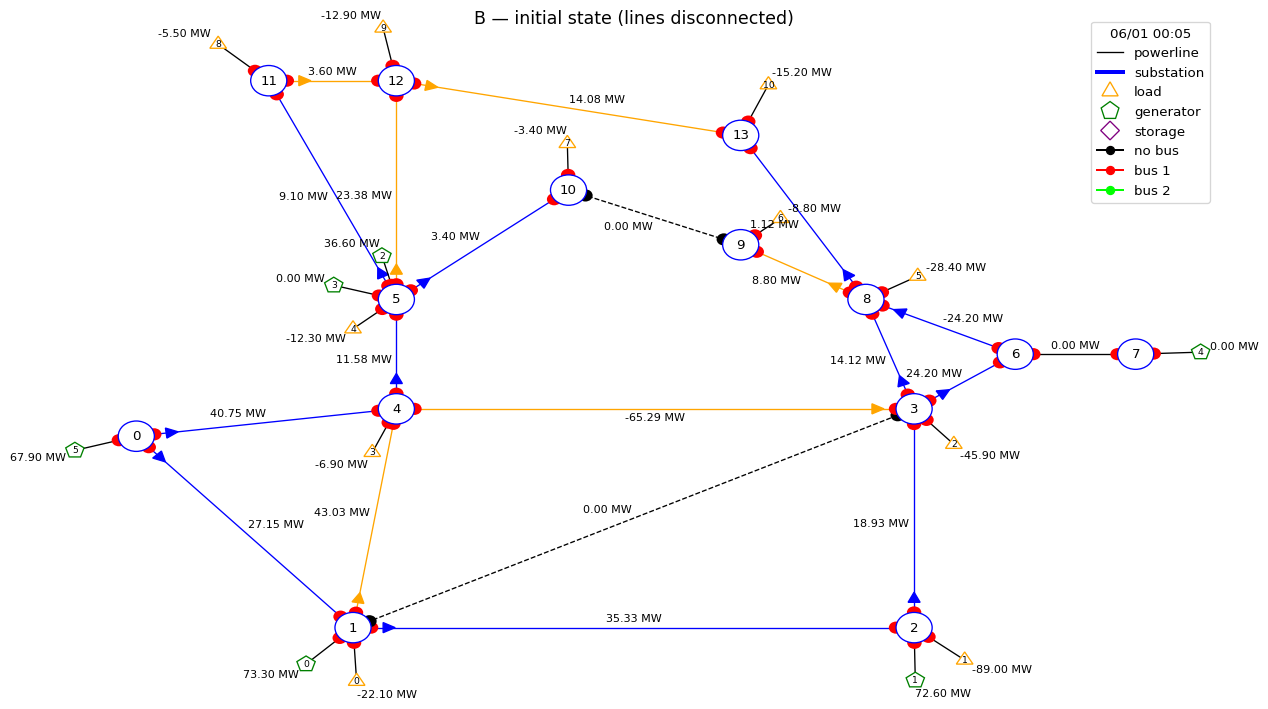

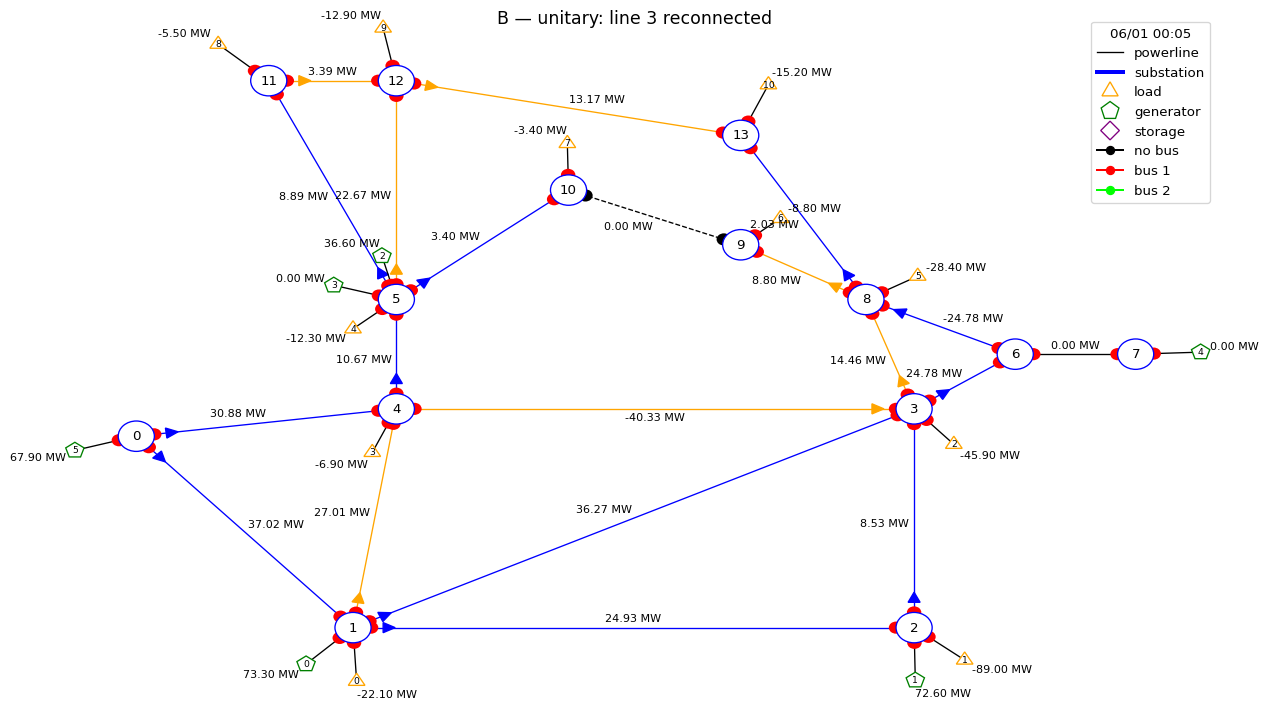

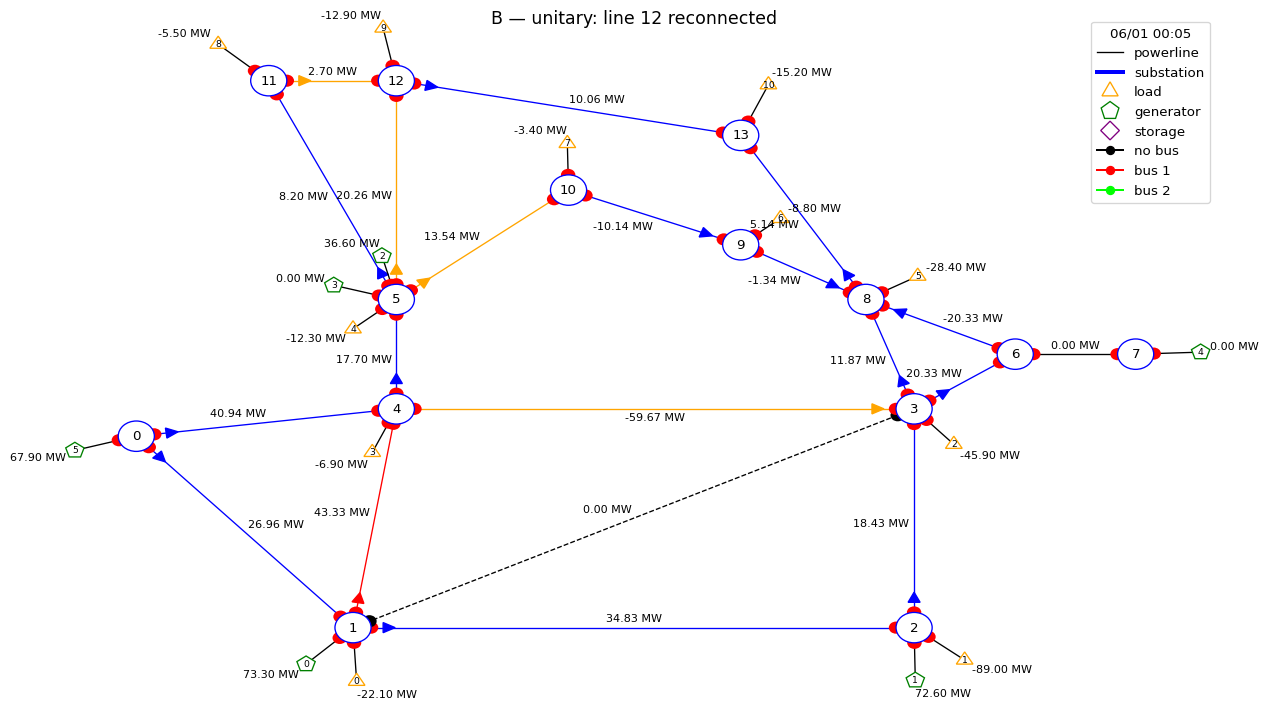

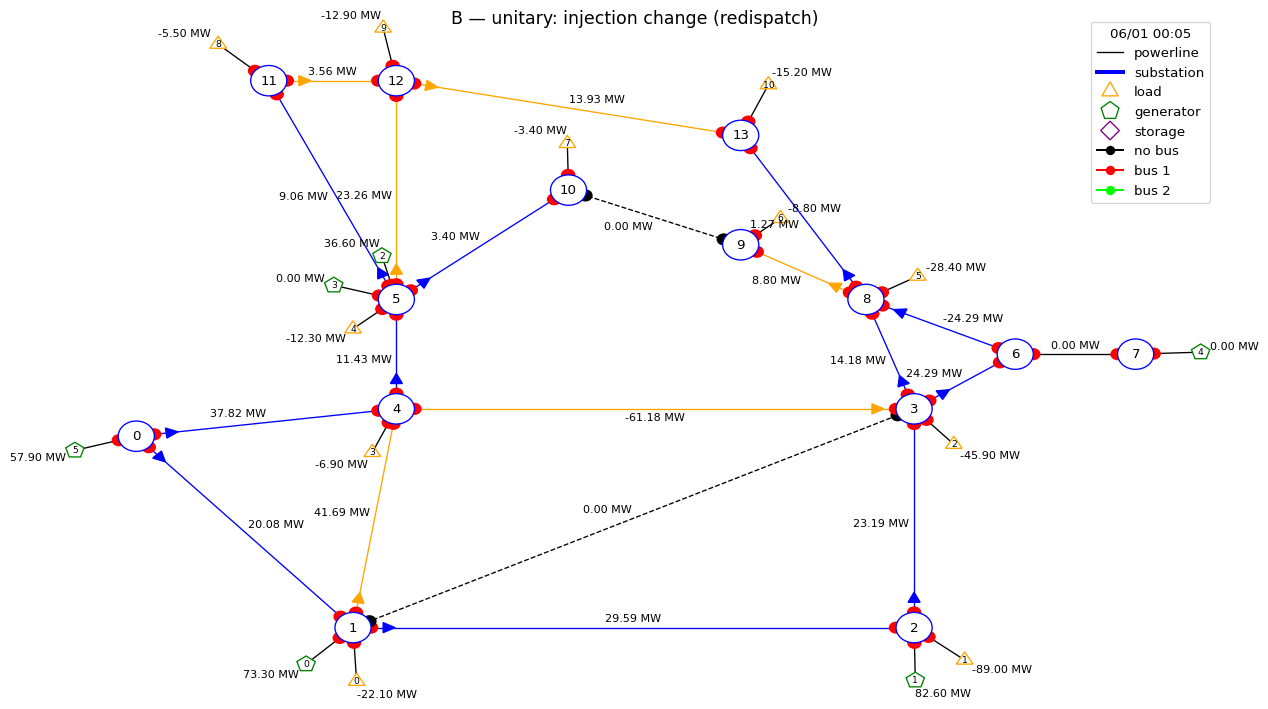

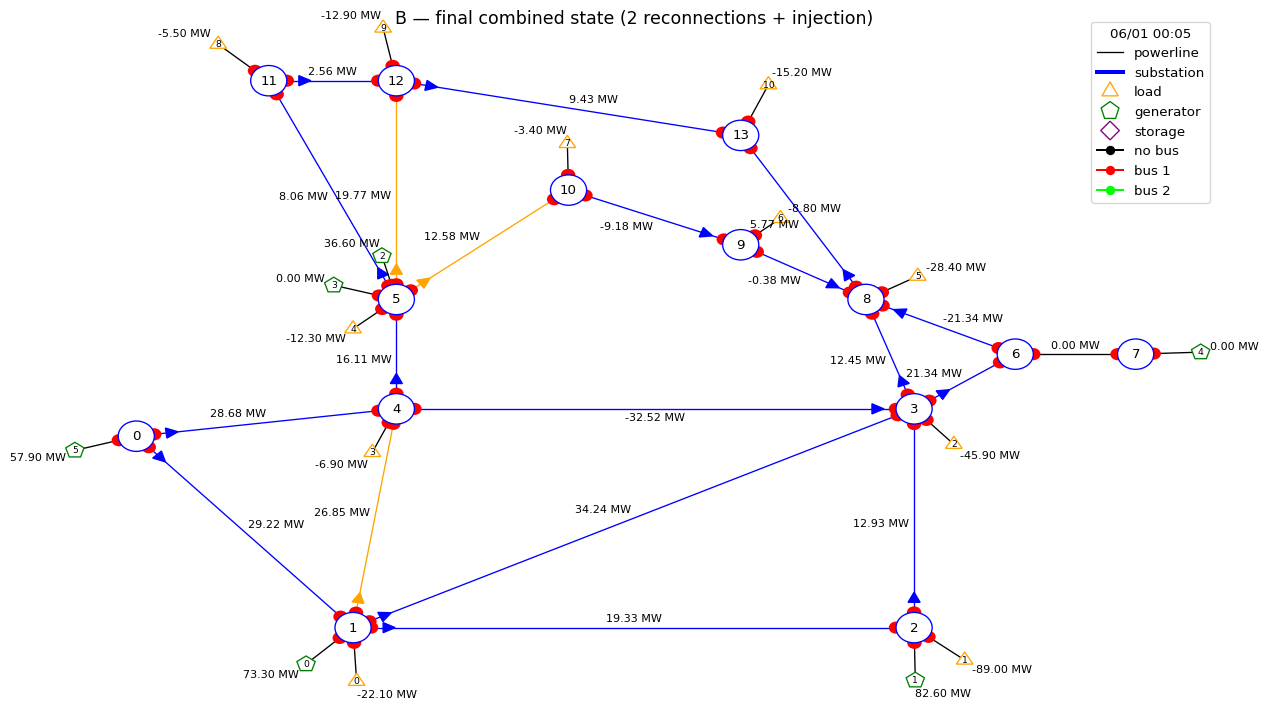

In [7]:
show(obs_start, "B — initial state (lines disconnected)")
show(obs1, f"B — unitary: line {id_l1} reconnected")
show(obs2, f"B — unitary: line {id_l2} reconnected")
show(obs_inj, "B — unitary: injection change (redispatch)")
show(obs_target, "B — final combined state (2 reconnections + injection)")

## Example C — two injection changes ($n_P=2$) + two line disconnections
Several injection changes simply add (standard superposition); the combined redispatch
equals $\delta P^1 + \delta P^2$ nodally.

In [8]:
env.set_id(0); env.reset()
obs_start, *_ = env.step(A({}))
dP1 = [(1, +6.0), (5, -6.0)]                                  # injection #1: sub 2 -> sub 0
dP2 = [(0, +4.0), (5, -4.0)]                                  # injection #2: sub 1 -> sub 0

obs1, *_ = obs_start.simulate(A({"set_line_status": [(id_l1, -1)]}), 0)
obs2, *_ = obs_start.simulate(A({"set_line_status": [(id_l2, -1)]}), 0)
obs_i1, *_ = obs_start.simulate(A({"redispatch": dP1}), 0)
obs_i2, *_ = obs_start.simulate(A({"redispatch": dP2}), 0)
combined = A({"set_line_status": [(id_l1, -1), (id_l2, -1)],
              "redispatch": [(0, +4.0), (1, +6.0), (5, -10.0)]})   # = dP1 + dP2
obs_target, *_ = obs_start.simulate(combined, 0)

p_gst = compute_flows_GST_from_unit_act_obs(
    [id_l1, id_l2], obs_start, [obs1, obs2], [obs_i1, obs_i2])
print(f"GST (2 injections + 2 disconnections)  Max difference (MW): {np.max(np.abs(obs_target.p_or - p_gst))}")
assert np.all(np.round(obs_target.p_or - p_gst, decimal_digit_precision) == 0.0)

GST (2 injections + 2 disconnections)  Max difference (MW): 6.849155141708252e-06


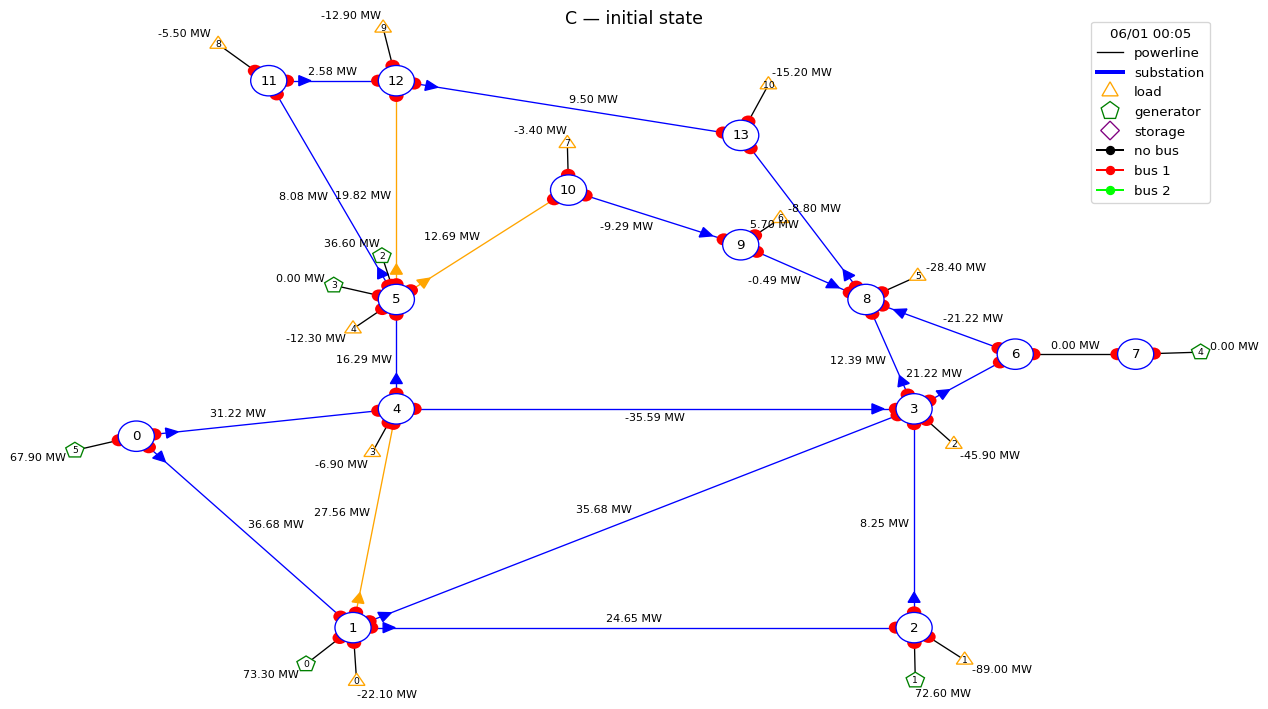

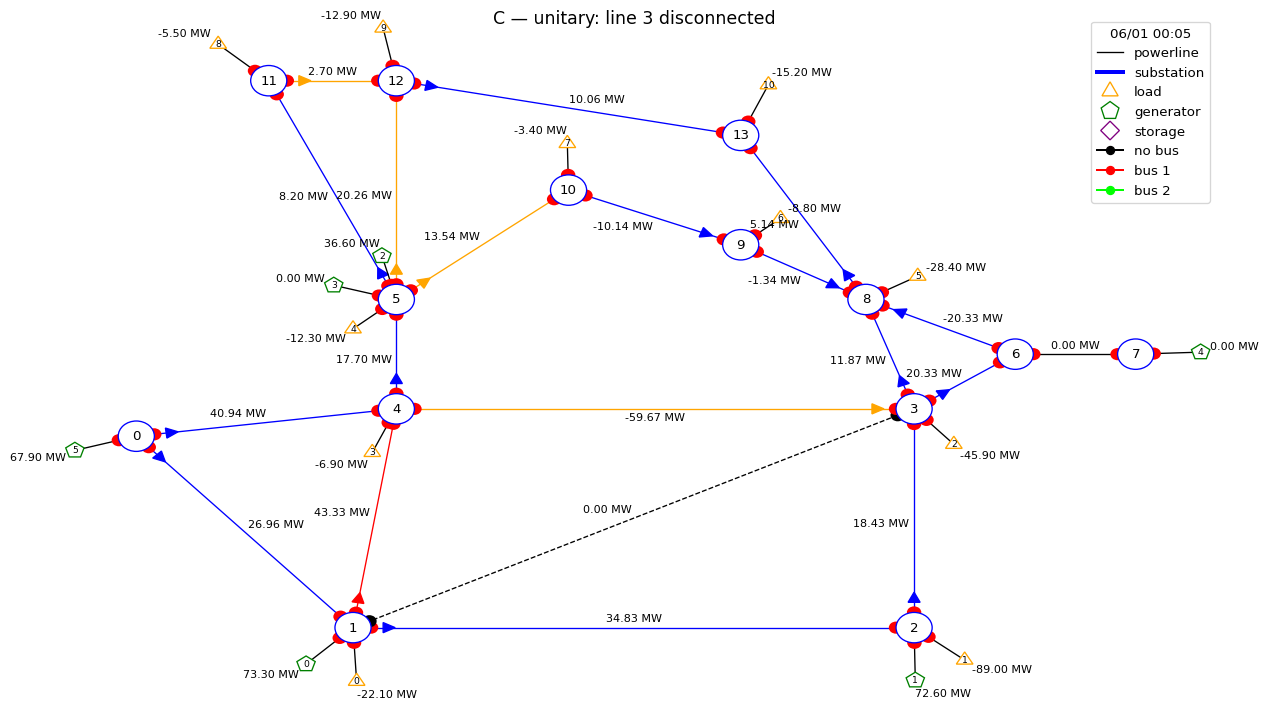

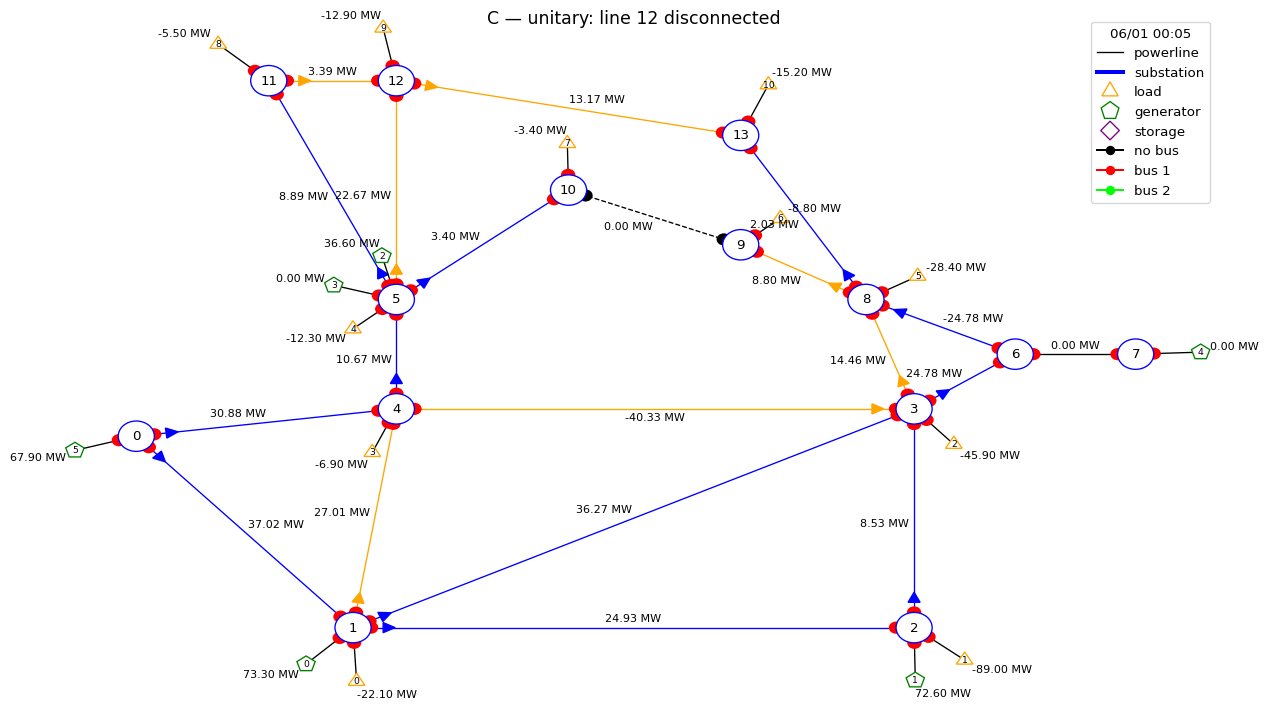

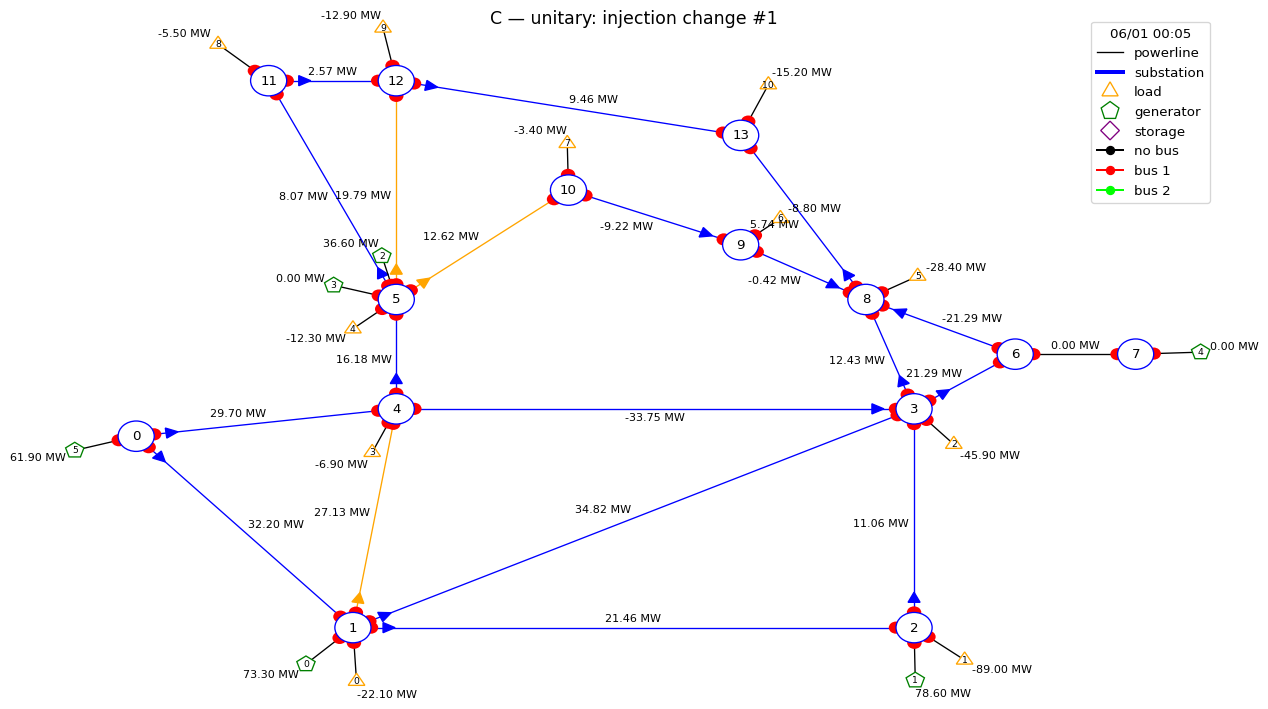

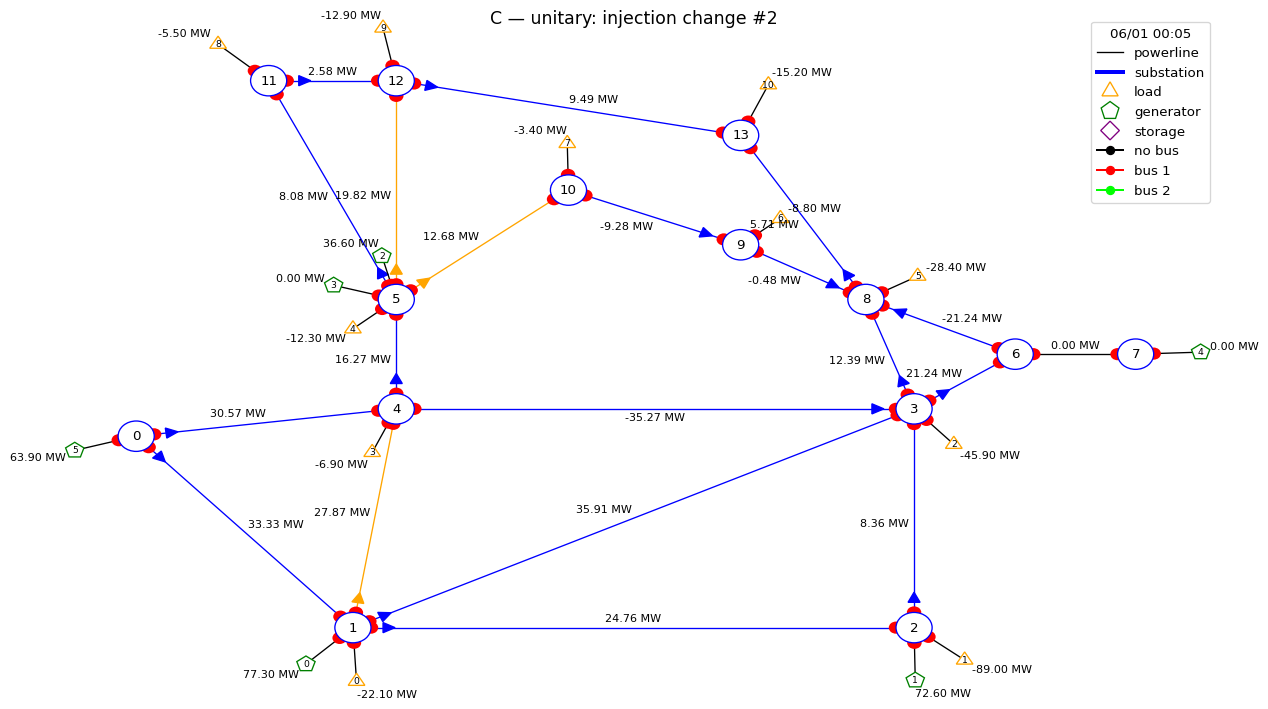

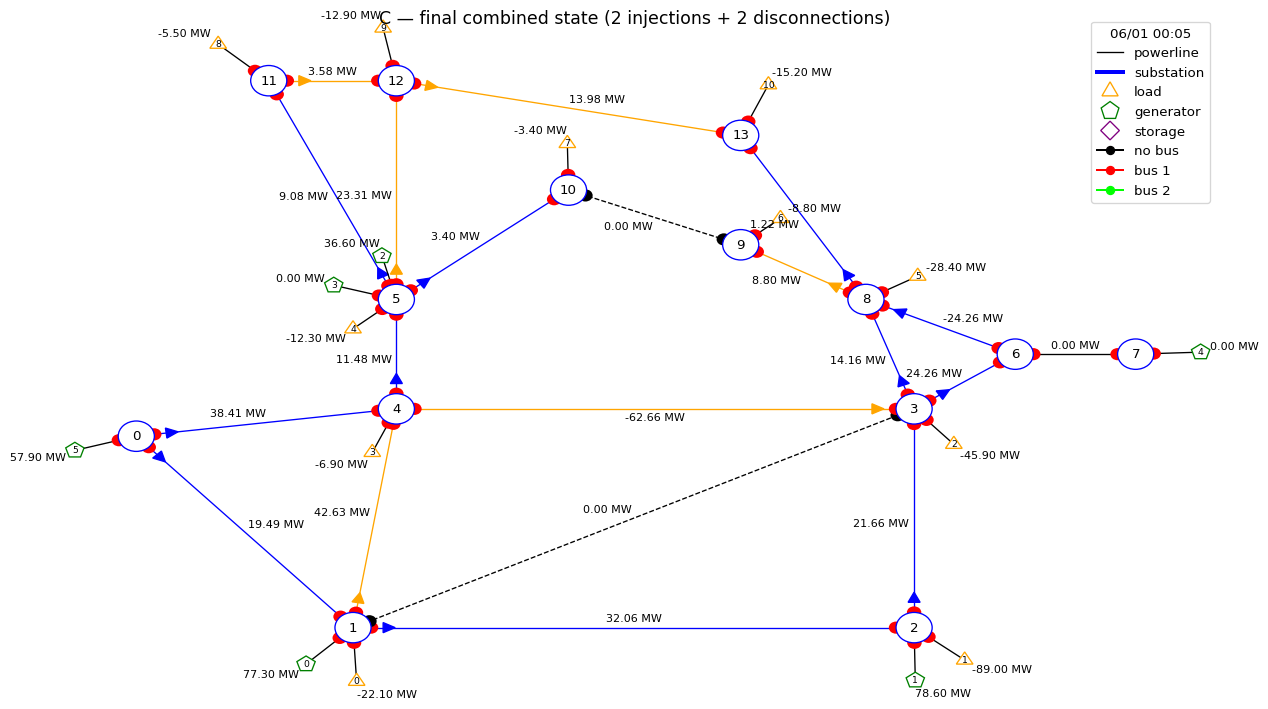

In [9]:
show(obs_start, "C — initial state")
show(obs1, f"C — unitary: line {id_l1} disconnected")
show(obs2, f"C — unitary: line {id_l2} disconnected")
show(obs_i1, "C — unitary: injection change #1")
show(obs_i2, "C — unitary: injection change #2")
show(obs_target, "C — final combined state (2 injections + 2 disconnections)")

## Substation actions (node split / merge) + injection
A substation reconfiguration is handled through its **virtual line** (as in the EST): a
**node split** behaves like a line *disconnection*, a **node merge** like a line
*reconnection*. The injection shifts these virtual sensitivities just like real-line ones.
Pass the substation ids through `idls_subs`, with `unit_act_observations` ordered
**lines first, then subs**.

### Example D — two node splits + an injection change

In [10]:
env.set_id(0); env.reset(); obs_start, *_ = env.step(A({}))
id_sub1, id_sub2 = 5, 4
act_s1 = {"set_bus": {"substations_id": [(5, (1, 1, 2, 2, 1, 2, 2))]}}
act_s2 = {"set_bus": {"substations_id": [(4, (2, 1, 2, 1, 2))]}}
obs1, *_ = obs_start.simulate(A(act_s1), 0)                 # substation unitary states
obs2, *_ = obs_start.simulate(A(act_s2), 0)
obs_inj, *_ = obs_start.simulate(A({"redispatch": redisp}), 0)
obs_target, *_ = obs_start.simulate(A(act_s1) + A(act_s2) + A({"redispatch": redisp}), 0)

p_gst, alpha, betas = compute_flows_GST_from_unit_act_obs(
    [], obs_start, [obs1, obs2], [obs_inj], idls_subs=[id_sub1, id_sub2], return_betas=True)
print("alpha =", round(alpha, 4), " betas =", np.round(betas, 4))
print(f"GST       Max difference (MW): {np.max(np.abs(obs_target.p_or - p_gst))}")
p_est_only = compute_flows_GST_from_unit_act_obs(
    [], obs_start, [obs1, obs2], [], idls_subs=[id_sub1, id_sub2])   # EST = GST without injection
print(f"EST only  Max difference (MW): {np.max(np.abs(obs_target.p_or - p_est_only)):.4f}")
assert np.all(np.round(obs_target.p_or - p_gst, decimal_digit_precision) == 0.0)

alpha = -0.5072  betas = [0.9364 0.5708]
GST       Max difference (MW): 2.7676672402776603e-06
EST only  Max difference (MW): 7.2928


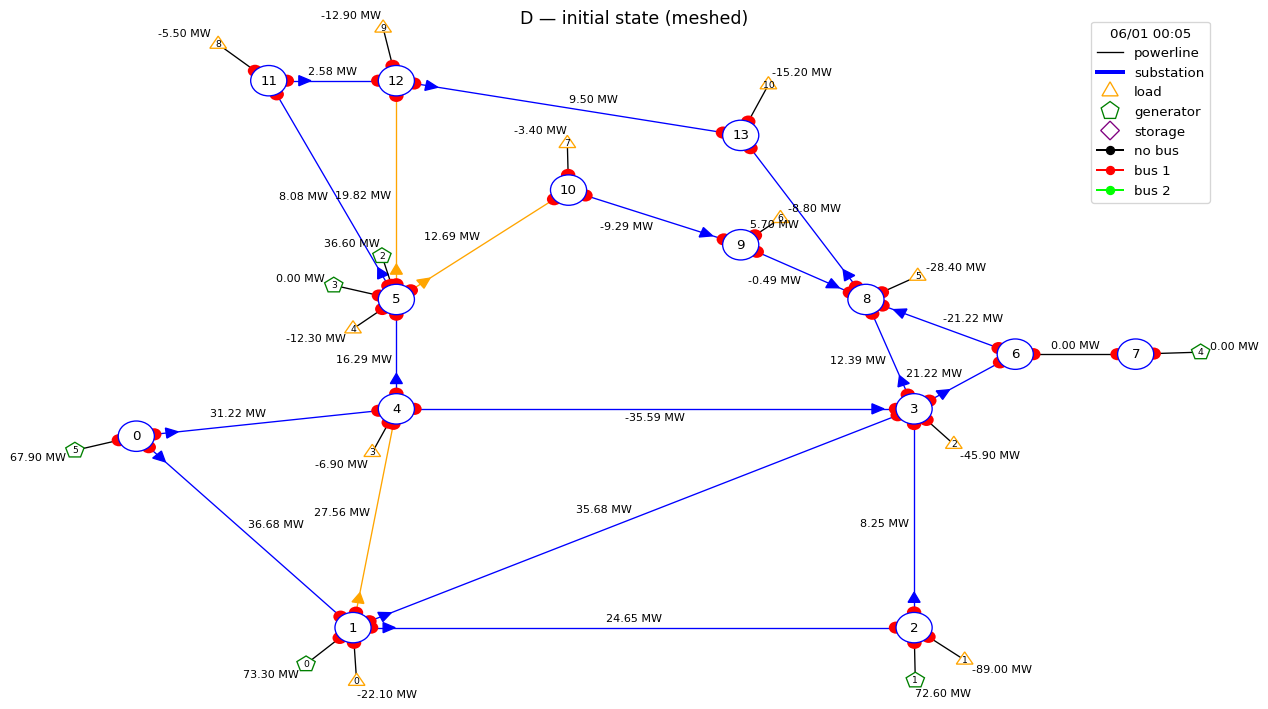

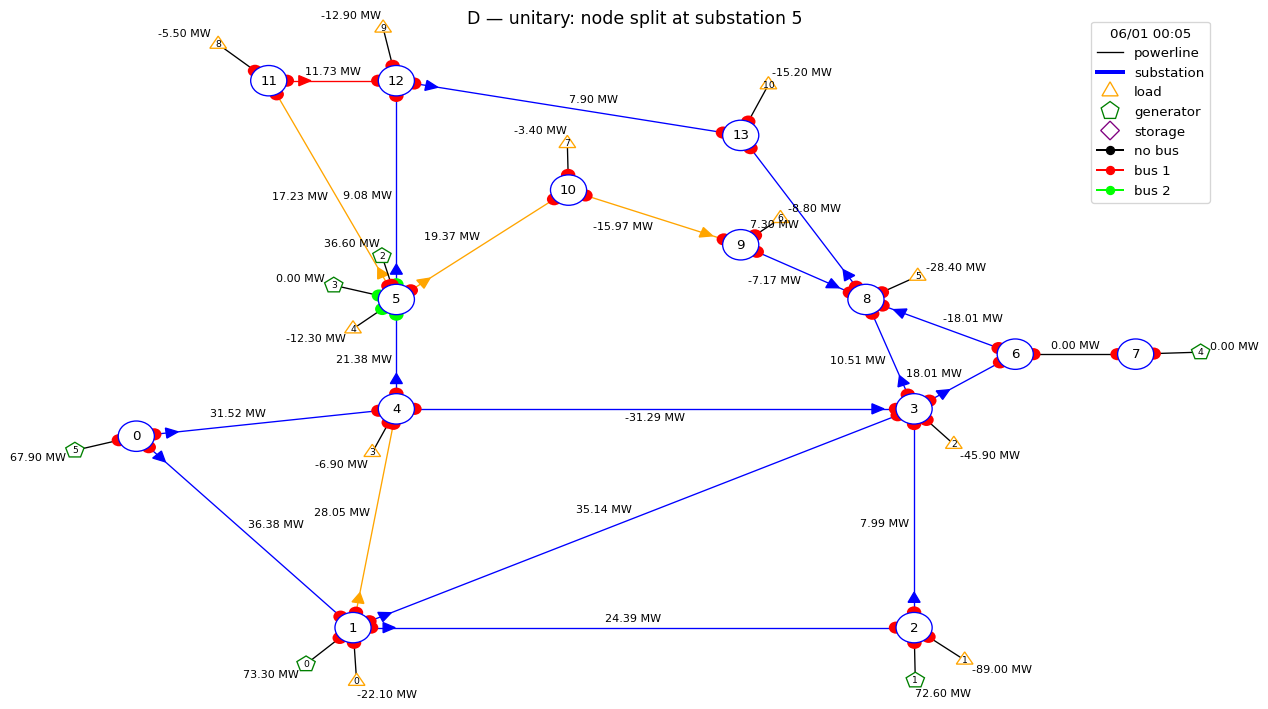

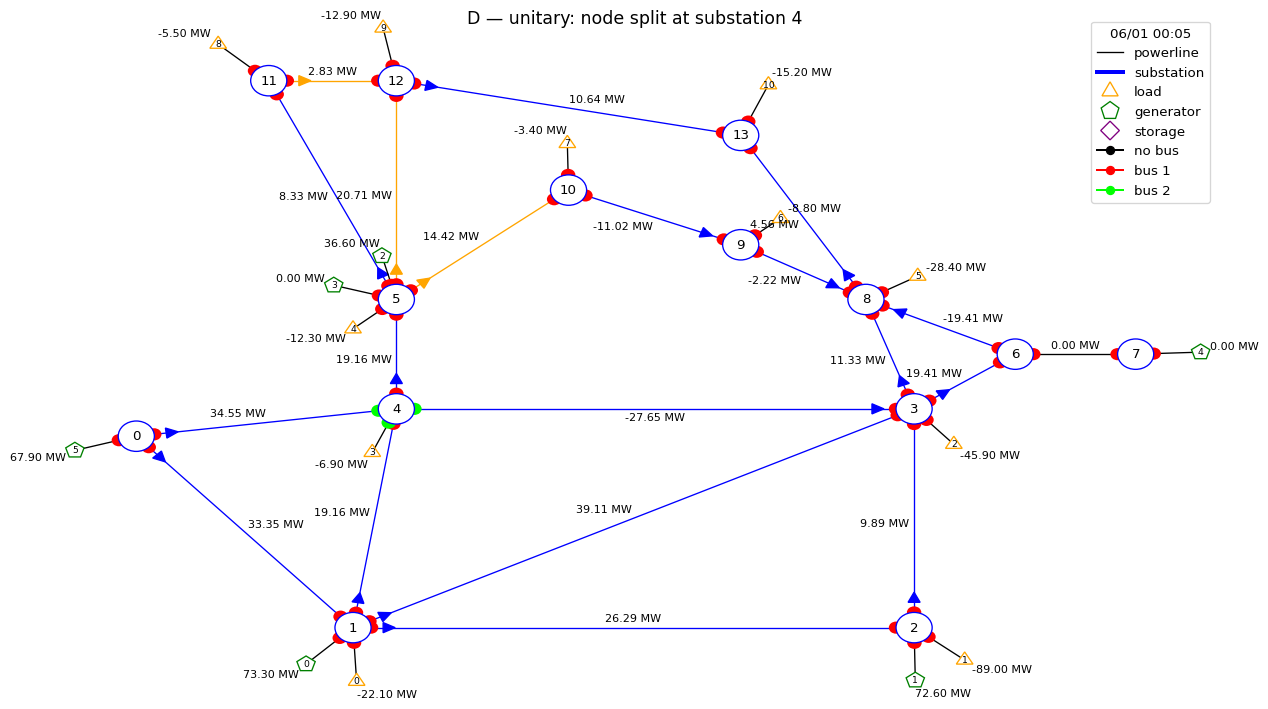

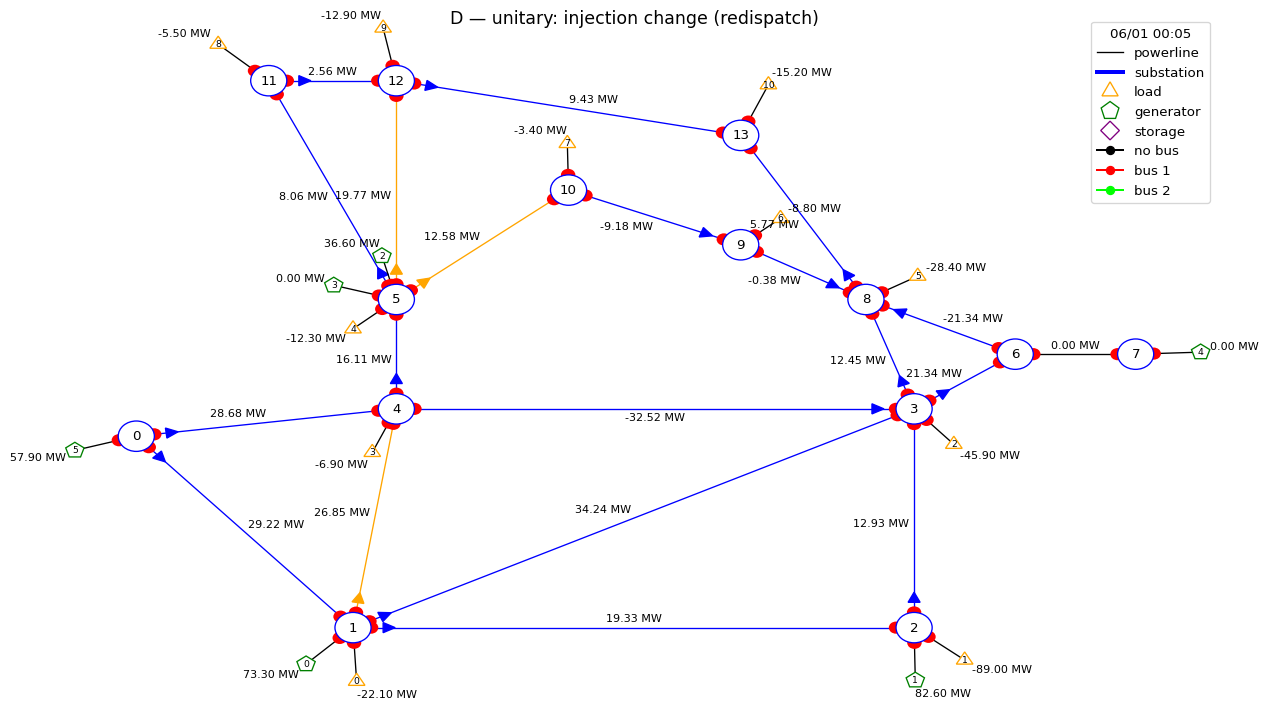

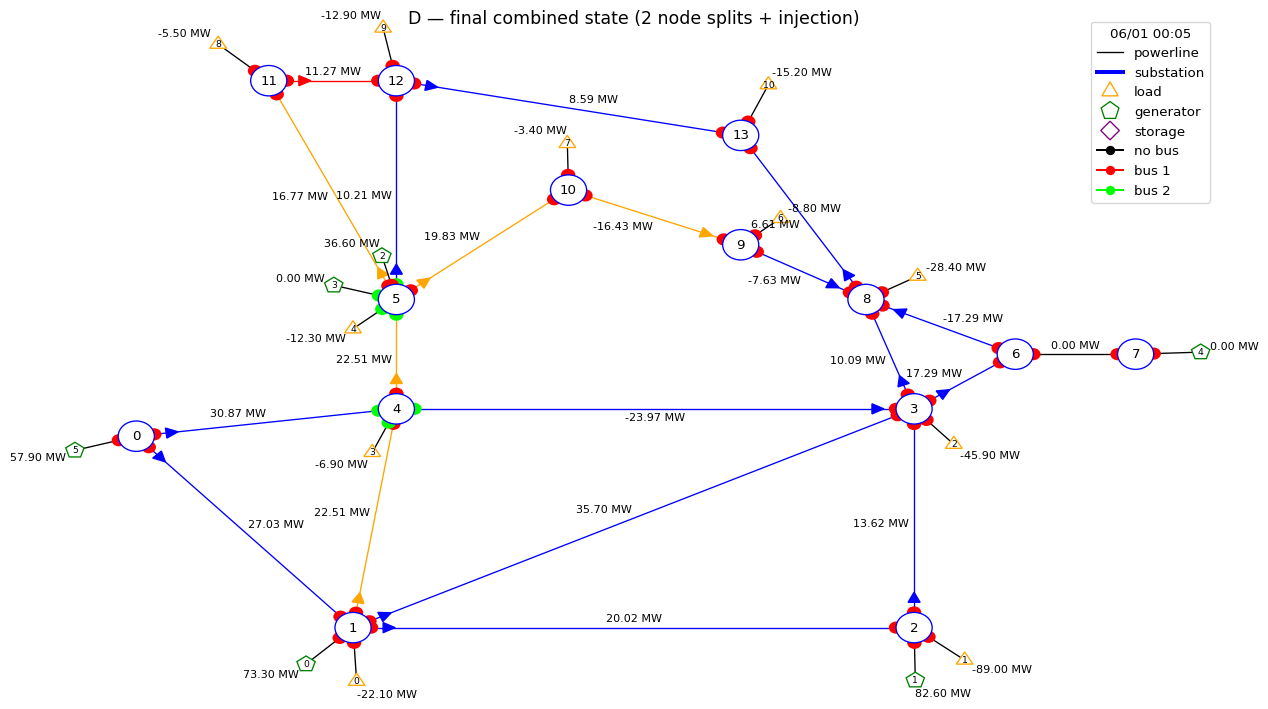

In [11]:
show(obs_start, "D — initial state (meshed)")
show(obs1, f"D — unitary: node split at substation {id_sub1}")
show(obs2, f"D — unitary: node split at substation {id_sub2}")
show(obs_inj, "D — unitary: injection change (redispatch)")
show(obs_target, "D — final combined state (2 node splits + injection)")

### Example E — mixed: a line disconnection **and** a node split, with an injection
Order the unitary observations lines-first, subs-last, and set `idls = idls_lines + idls_subs`.

In [12]:
env.set_id(0); env.reset(); obs_start, *_ = env.step(A({}))
id_l, id_sub = 3, 5
act_line = {"set_line_status": [(id_l, -1)]}
act_sub = {"set_bus": {"substations_id": [(5, (1, 1, 2, 2, 1, 2, 2))]}}
obs_l, *_ = obs_start.simulate(A(act_line), 0)     # line action first
obs_s, *_ = obs_start.simulate(A(act_sub), 0)      # sub action last
obs_inj, *_ = obs_start.simulate(A({"redispatch": redisp}), 0)
obs_target, *_ = obs_start.simulate(A(act_line) + A(act_sub) + A({"redispatch": redisp}), 0)

p_gst, alpha, betas = compute_flows_GST_from_unit_act_obs(
    [id_l], obs_start, [obs_l, obs_s], [obs_inj], idls_subs=[id_sub], return_betas=True)
print("alpha =", round(alpha, 4), " betas =", np.round(betas, 4))
print(f"GST (line disconnection + node split + injection)  Max difference (MW): {np.max(np.abs(obs_target.p_or - p_gst))}")
assert np.all(np.round(obs_target.p_or - p_gst, decimal_digit_precision) == 0.0)

alpha = -0.8952  betas = [0.9455 0.9497]
GST (line disconnection + node split + injection)  Max difference (MW): 3.171389195699703e-06


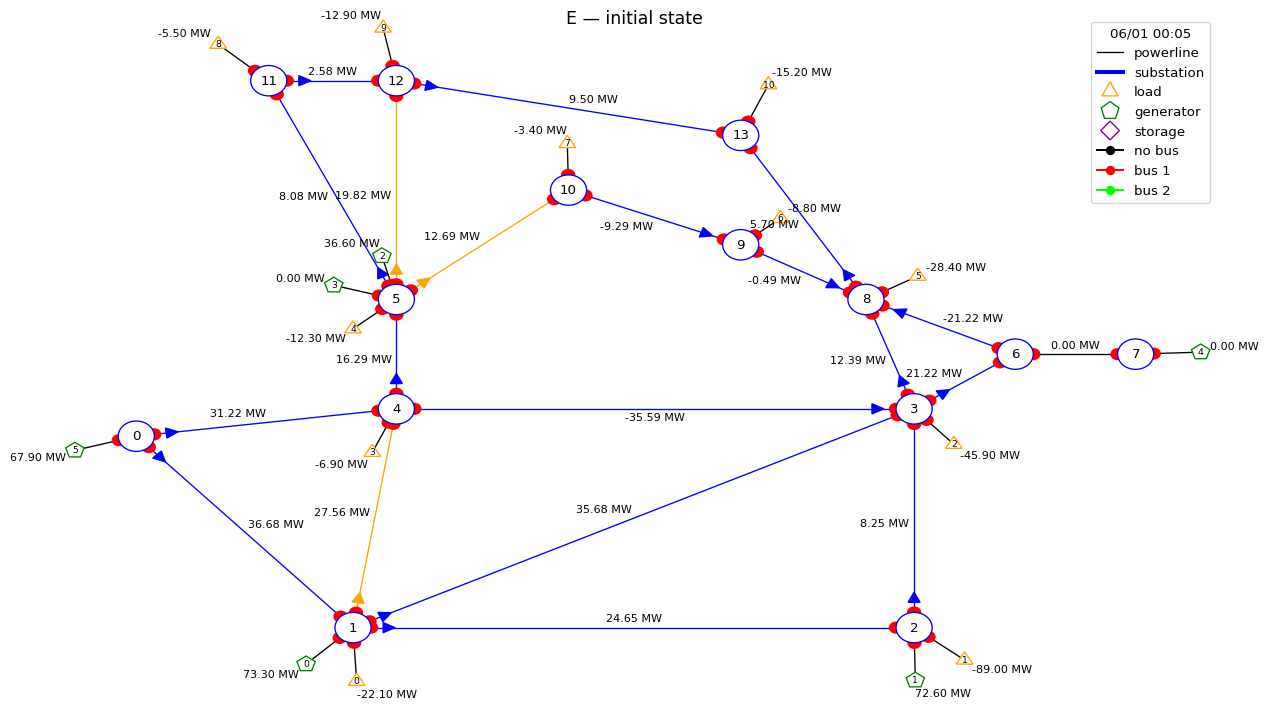

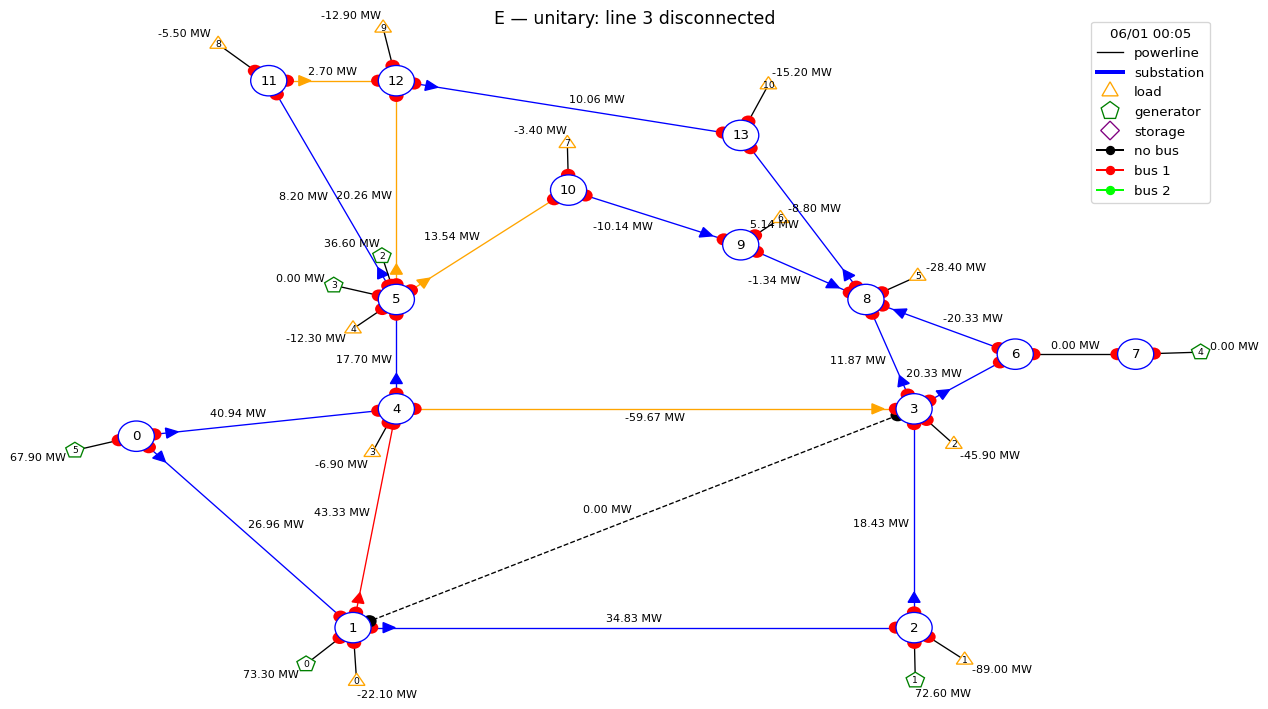

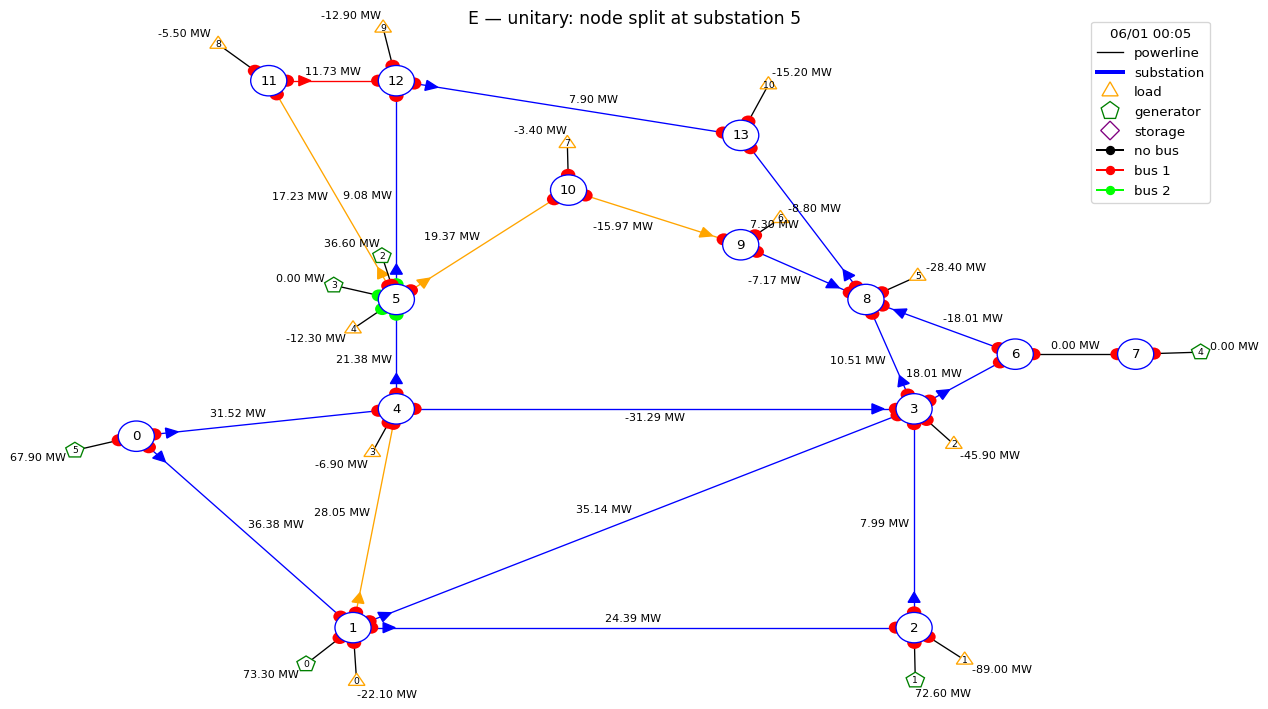

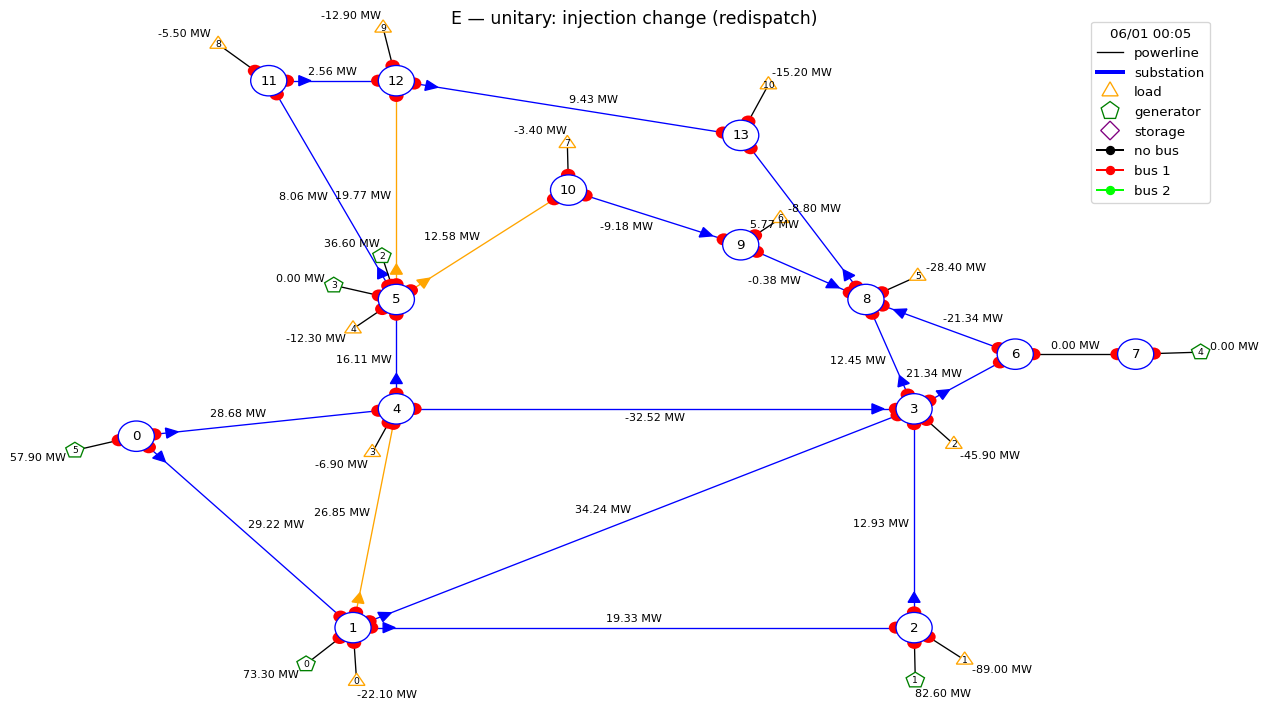

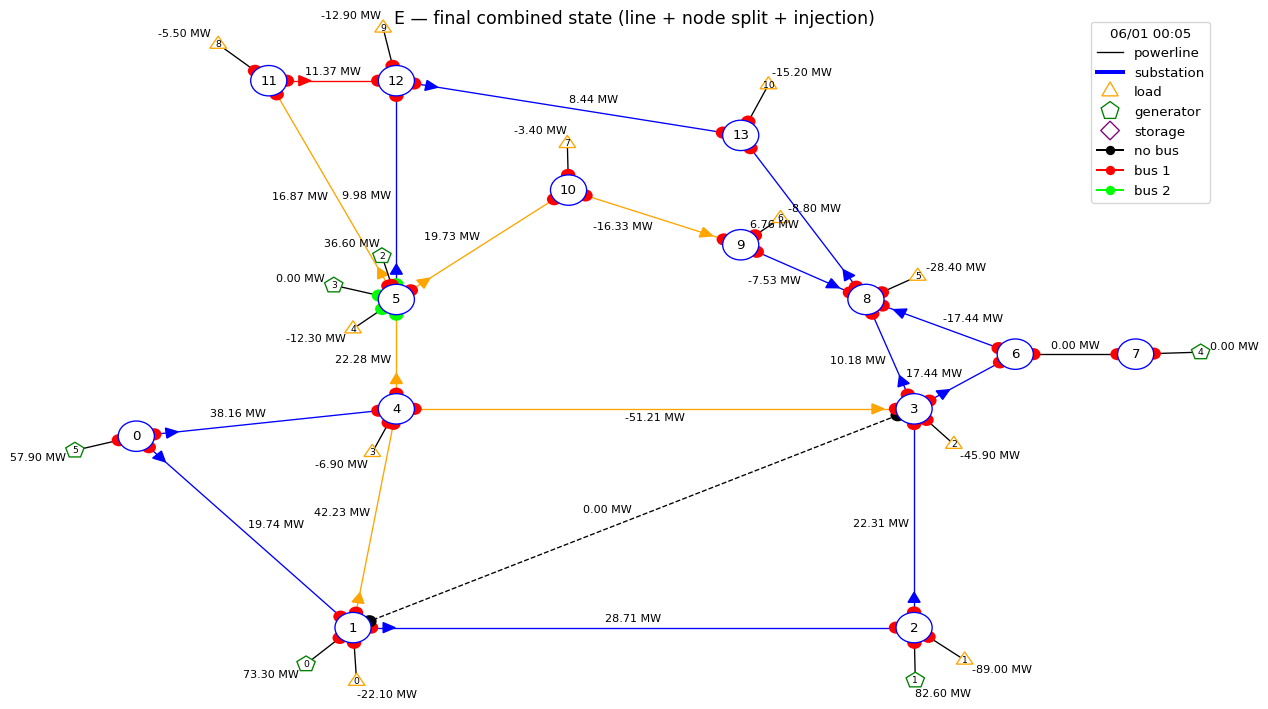

In [13]:
show(obs_start, "E — initial state")
show(obs_l, f"E — unitary: line {id_l} disconnected")
show(obs_s, f"E — unitary: node split at substation {id_sub}")
show(obs_inj, "E — unitary: injection change (redispatch)")
show(obs_target, "E — final combined state (line + node split + injection)")

## Summary
* The GST reconstructs the combined **injection + topology** target flows from the
  precomputed unitary states only, with **no new power-flow solve** — matching the full DC
  solver to the notebook's 4-decimal accuracy, as the network-flow figures confirm visually.
* The topology states keep the EST weights; the injection states add in pure superposition;
  the injection enters the weights **only through the right-hand side**.
* `injection_observations = []` recovers the EST exactly. Substation split/merge actions are
  supported via `idls_subs` (node split = virtual-line disconnection, node merge = virtual-line
  reconnection), including mixed with line actions. For same-kind line combinations the
  `State.compute_flows_gst(...)` object API is also available.